# ***MINOR PROJECT***
# Spotify Songs’ Genre Segmentation
**Corizo Internship · Minor Project**  

**Kanishk V P**

**B.Tech Computer Science and Engineering**

## Abstract
This project groups songs by their audio characteristics using K-Means clustering. It explores the supplied Spotify dataset, compares the groups with playlist genres and playlist names, and builds a small content-based recommendation function. Genre labels are used to interpret the results after clustering, rather than to train the model.

The analysis follows the supplied project brief. The notebook contains the complete supplied CSV in compressed form, so no API keys, Spotify account, Kaggle credentials, or separate data upload are needed.

**Execution:** Google Colab → Runtime → Run all. A CPU runtime is sufficient. All charts, tables, conclusions, and exports are regenerated from the data. The first run may take a few minutes.

## 1. Objective and approach
The aim is to find groups of songs with similar sound profiles and use those groups to suggest related songs.

1. Check missing values, repeated tracks, and audio feature ranges.
2. Explore audio distributions, correlations, genres, and playlists.
3. Standardize continuous audio features and compare several values of K.
4. Interpret the selected clusters and compare their playlist memberships.
5. Rank similar songs within the same cluster and export the results.

**Scope:** Audio similarity is not the same as a verified genre label or personal preference. This dataset has no listening histories or user ratings, so recommendation relevance cannot be measured as user accuracy.

In [ ]:
import sys
import subprocess
import importlib.util

# Colab normally includes these packages. Install only a missing dependency.
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "sklearn": "scikit-learn", "joblib": "joblib"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import base64
import gzip
import hashlib
import io
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from threadpoolctl import threadpool_limits

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 55)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


## 2. Load the supplied dataset
The embedded bytes are the original `spotify dataset.csv` from the project ZIP. A SHA-256 check confirms that decompression reconstructs the original file. The long data cell can remain collapsed during review.

In [ ]:
# Embedded source data; no network request is used here.
DATA_GZIP_BASE64 = "..."
csv_bytes = gzip.decompress(base64.b64decode(DATA_GZIP_BASE64))
assert hashlib.sha256(csv_bytes).hexdigest() == "9902920cfe4940f0914ebb6716801a42f7f19ac88fbd6693eaae7e2822b16845", "Dataset integrity check failed."
raw_df = pd.read_csv(io.BytesIO(csv_bytes))
print(f"Original dataset: {raw_df.shape[0]:,} records × {raw_df.shape[1]} columns")
display(raw_df.head())

Original dataset: 32,833 records × 23 columns


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxury Remix,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury Remix],2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [ ]:
AUDIO_FEATURES = ["danceability", "energy", "loudness", "speechiness",
                  "acousticness", "instrumentalness", "liveness", "valence",
                  "tempo", "duration_ms"]
required = {"track_id", "track_name", "track_artist", "playlist_genre",
            "playlist_name", "playlist_id", "track_popularity", *AUDIO_FEATURES}
assert required.issubset(raw_df.columns), "Required columns are missing."

audit = pd.DataFrame({"dtype": raw_df.dtypes.astype(str),
                      "missing": raw_df.isna().sum(),
                      "unique_values": raw_df.nunique()})
display(audit)
print("Exact duplicate records:", raw_df.duplicated().sum())
print("Unique track IDs:", raw_df.track_id.nunique())
display(raw_df[AUDIO_FEATURES + ["track_popularity"]].describe().round(3))

,dtype,missing,unique_values
track_id,object,0,28356
track_name,object,5,23449
track_artist,object,5,10692
track_popularity,int64,0,101
track_album_id,object,0,22545
track_album_name,object,5,19743
track_album_release_date,object,0,4530
playlist_name,object,0,449
playlist_id,object,0,471
playlist_genre,object,0,6


Exact duplicate records: 0
Unique track IDs: 28356


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,track_popularity
count,32833.000,32833.000,32833.000,32833.000,32833.000,32833.000,32833.000,32833.000,32833.000,32833.000,32833.000
mean,0.655,0.699,-6.719,0.107,0.175,0.085,0.190,0.511,120.881,225799.812,42.477
std,0.145,0.181,2.988,0.101,0.220,0.224,0.154,0.233,26.904,59834.006,24.984
min,0.000,0.000,-46.448,0.000,0.000,0.000,0.000,0.000,0.000,4000.000,0.000
25%,0.563,0.581,-8.171,0.041,0.015,0.000,0.093,0.331,99.960,187819.000,24.000
50%,0.672,0.721,-6.166,0.062,0.080,0.000,0.127,0.512,121.984,216000.000,45.000
75%,0.761,0.840,-4.645,0.132,0.255,0.005,0.248,0.693,133.918,253585.000,62.000
max,0.983,1.000,1.275,0.918,0.994,0.994,0.996,0.991,239.440,517810.000,100.000


## 3. Data preparation
A track can occur in more than one playlist. These memberships are useful information, but repeating the same track in model fitting would give it extra weight. The model therefore uses one row per track ID. A separate membership table preserves its playlist and genre associations.

Rows without a track ID, song name, or artist are removed so the recommendation results remain identifiable. Numeric columns are converted explicitly; impossible ranges become missing values and are median-imputed in the preprocessing pipeline. Valid extreme values are retained. When repeated IDs have different audio values, their median is used.

Popularity is excluded because it measures audience response. Playlist labels, IDs, names, and album metadata are also excluded. Key and mode are left out of this baseline because a numeric key code does not represent an ordinary Euclidean distance between musical keys.

In [ ]:
clean = raw_df.drop_duplicates().dropna(subset=["track_id", "track_name", "track_artist"]).copy()
for col in AUDIO_FEATURES:
    clean[col] = pd.to_numeric(clean[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
bounded = ["danceability", "energy", "speechiness", "acousticness",
           "instrumentalness", "liveness", "valence"]
invalid_counts = {}
for col in bounded:
    invalid = clean[col].notna() & ~clean[col].between(0, 1)
    invalid_counts[col] = int(invalid.sum())
    clean.loc[invalid, col] = np.nan
for col in ["tempo", "duration_ms"]:
    invalid = clean[col].notna() & clean[col].le(0)
    invalid_counts[col] = int(invalid.sum())
    clean.loc[invalid, col] = np.nan

memberships = clean[["track_id", "playlist_id", "playlist_name",
                     "playlist_genre", "playlist_subgenre"]].drop_duplicates()
audio_conflicts = clean.groupby("track_id")[AUDIO_FEATURES].nunique().gt(1).sum()
metadata_cols = ["track_id", "track_name", "track_artist", "track_popularity"]
songs = clean[metadata_cols].drop_duplicates("track_id").merge(
    clean.groupby("track_id", as_index=False)[AUDIO_FEATURES].median(),
    on="track_id", validate="one_to_one")
genre_sets = memberships.groupby("track_id")["playlist_genre"].agg(
    lambda values: ", ".join(sorted(set(values.dropna()))))
songs["playlist_genres"] = songs.track_id.map(genre_sets)
songs["duration_min"] = songs.duration_ms / 60000
songs = songs.reset_index(drop=True)
assert songs.track_id.is_unique
assert songs[AUDIO_FEATURES].notna().any().all(), "An audio column is entirely missing."

preprocessing_log = pd.DataFrame({
    "measure": ["Original records", "Records after identity cleaning",
                "Unique tracks for clustering", "Extra track occurrences removed from fitting",
                "Missing audio cells before imputation"],
    "value": [len(raw_df), len(clean), len(songs), len(clean)-len(songs),
              int(songs[AUDIO_FEATURES].isna().sum().sum())]})
display(preprocessing_log)
print("Invalid range counts:", invalid_counts)
print("Track IDs with conflicting values, by feature:", audio_conflicts.to_dict())

,measure,value
0,Original records,32833
1,Records after identity cleaning,32828
2,Unique tracks for clustering,28352
3,Extra track occurrences removed from fitting,4476
4,Missing audio cells before imputation,1


Invalid range counts: {'danceability': 0, 'energy': 0, 'speechiness': 0, 'acousticness': 0, 'instrumentalness': 0, 'liveness': 0, 'valence': 0, 'tempo': 1, 'duration_ms': 0}
Track IDs with conflicting values, by feature: {'danceability': 0, 'energy': 0, 'loudness': 0, 'speechiness': 0, 'acousticness': 0, 'instrumentalness': 0, 'liveness': 0, 'valence': 0, 'tempo': 0, 'duration_ms': 0}


## 4. Exploratory analysis
The audio plots use unique tracks. Genre and playlist charts use the preserved membership table, counting each track once per displayed genre or playlist. A song may therefore contribute to more than one category.

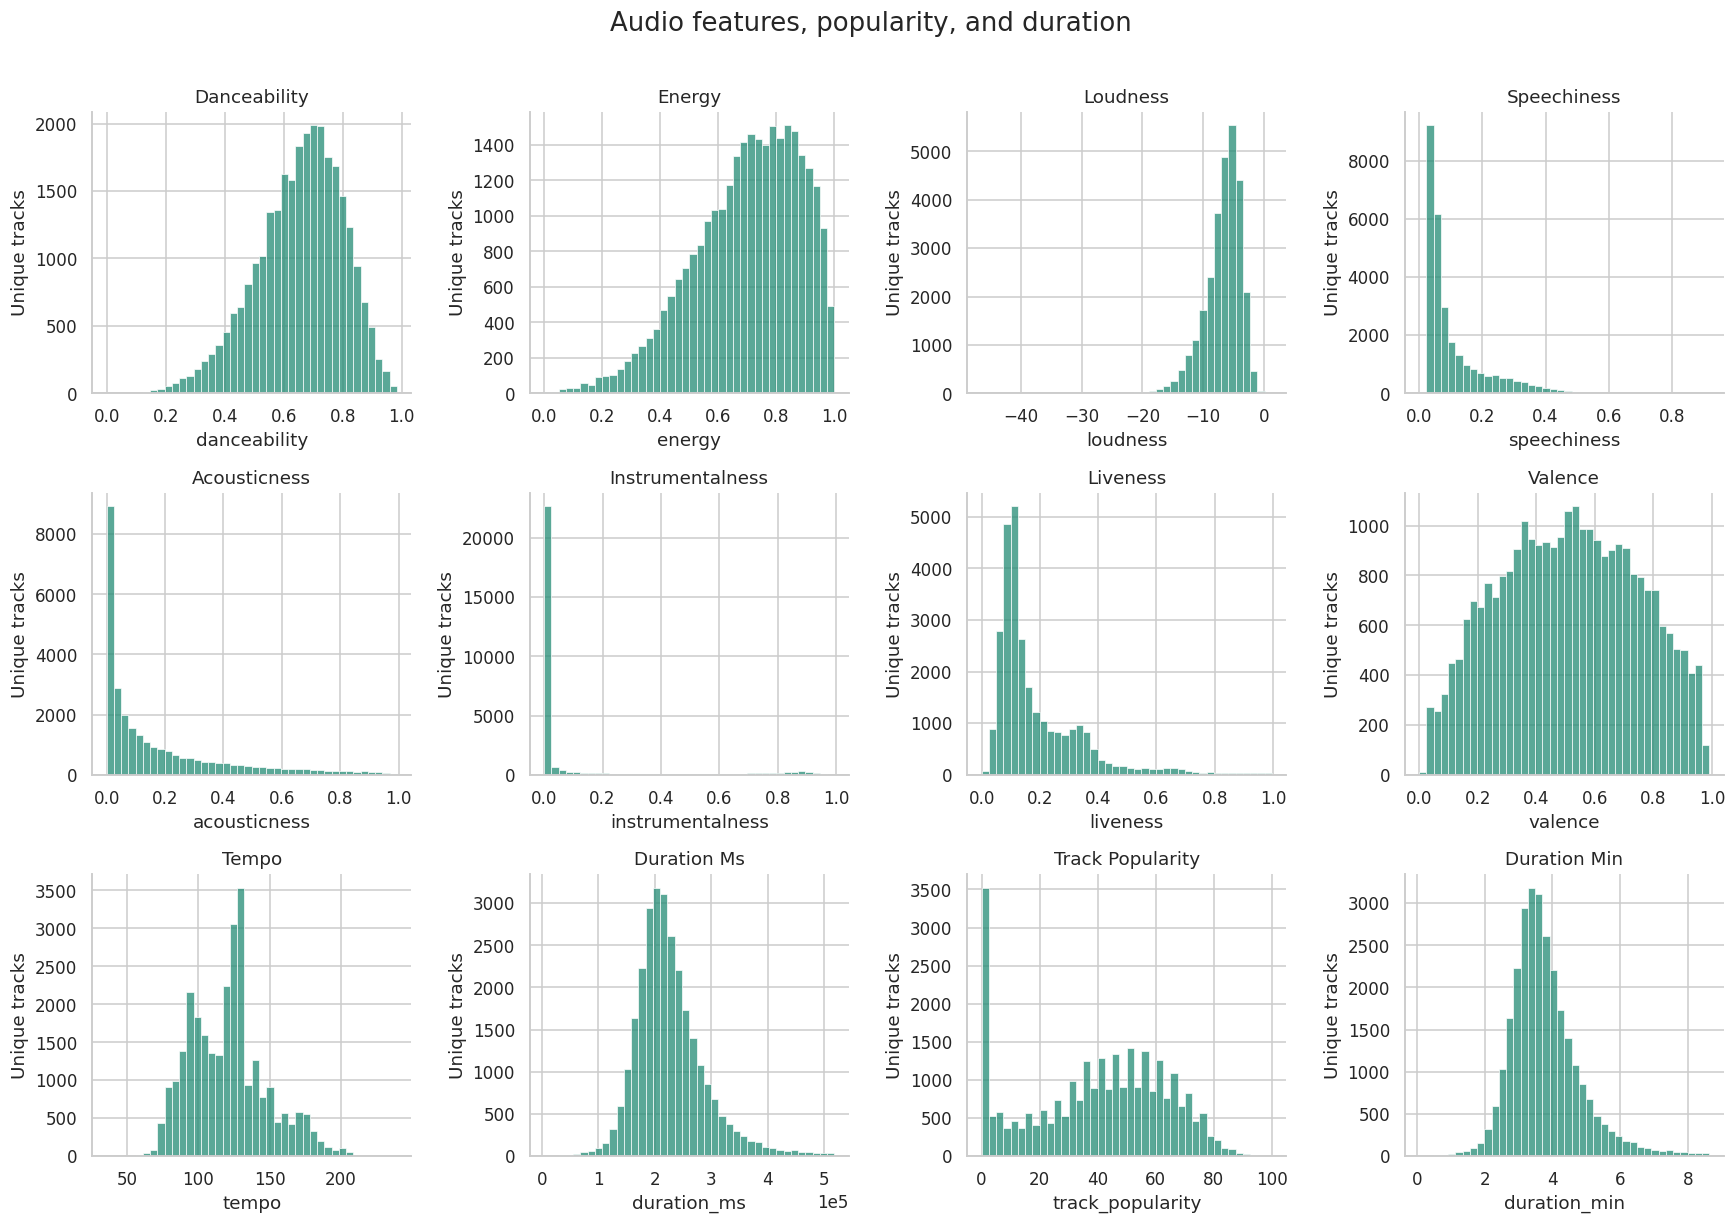

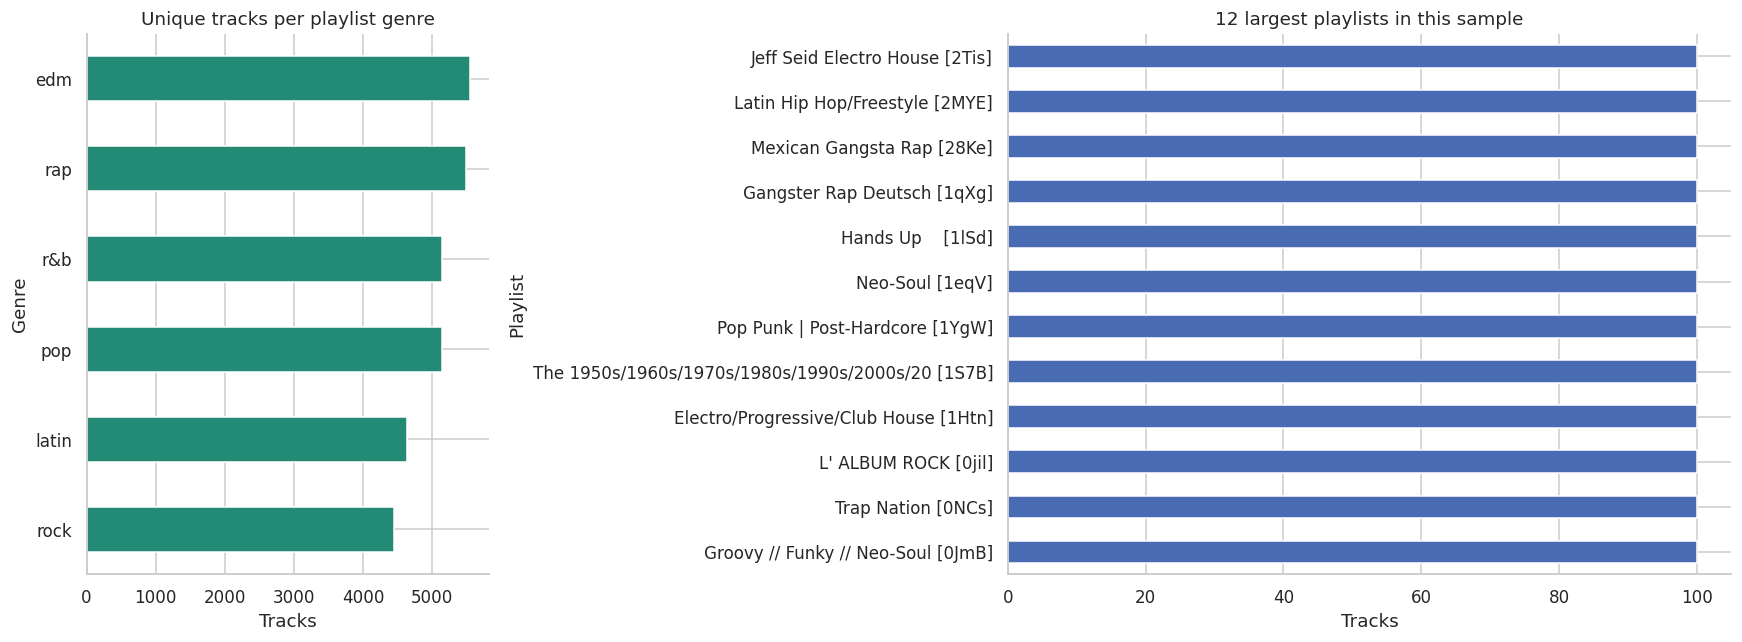

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, col in zip(axes.flat, AUDIO_FEATURES + ["track_popularity", "duration_min"]):
    sns.histplot(data=songs, x=col, bins=40, ax=ax, color="#238b75")
    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel("Unique tracks")
    if col == "duration_ms":
        ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
fig.suptitle("Audio features, popularity, and duration", fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

genre_counts = memberships.groupby("playlist_genre").track_id.nunique().sort_values()
top_playlists = (memberships.groupby(["playlist_id", "playlist_name"]).track_id.nunique()
                 .nlargest(12).sort_values())
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.8]})
genre_counts.plot.barh(ax=axes[0], color="#238b75")
axes[0].set(title="Unique tracks per playlist genre", xlabel="Tracks", ylabel="Genre")
pd.Series(top_playlists.values, index=[f"{name[:42]} [{pid[:4]}]"
          for pid, name in top_playlists.index]).plot.barh(ax=axes[1], color="#486bb3")
axes[1].set(title="12 largest playlists in this sample", xlabel="Tracks", ylabel="Playlist")
plt.tight_layout()
plt.show()

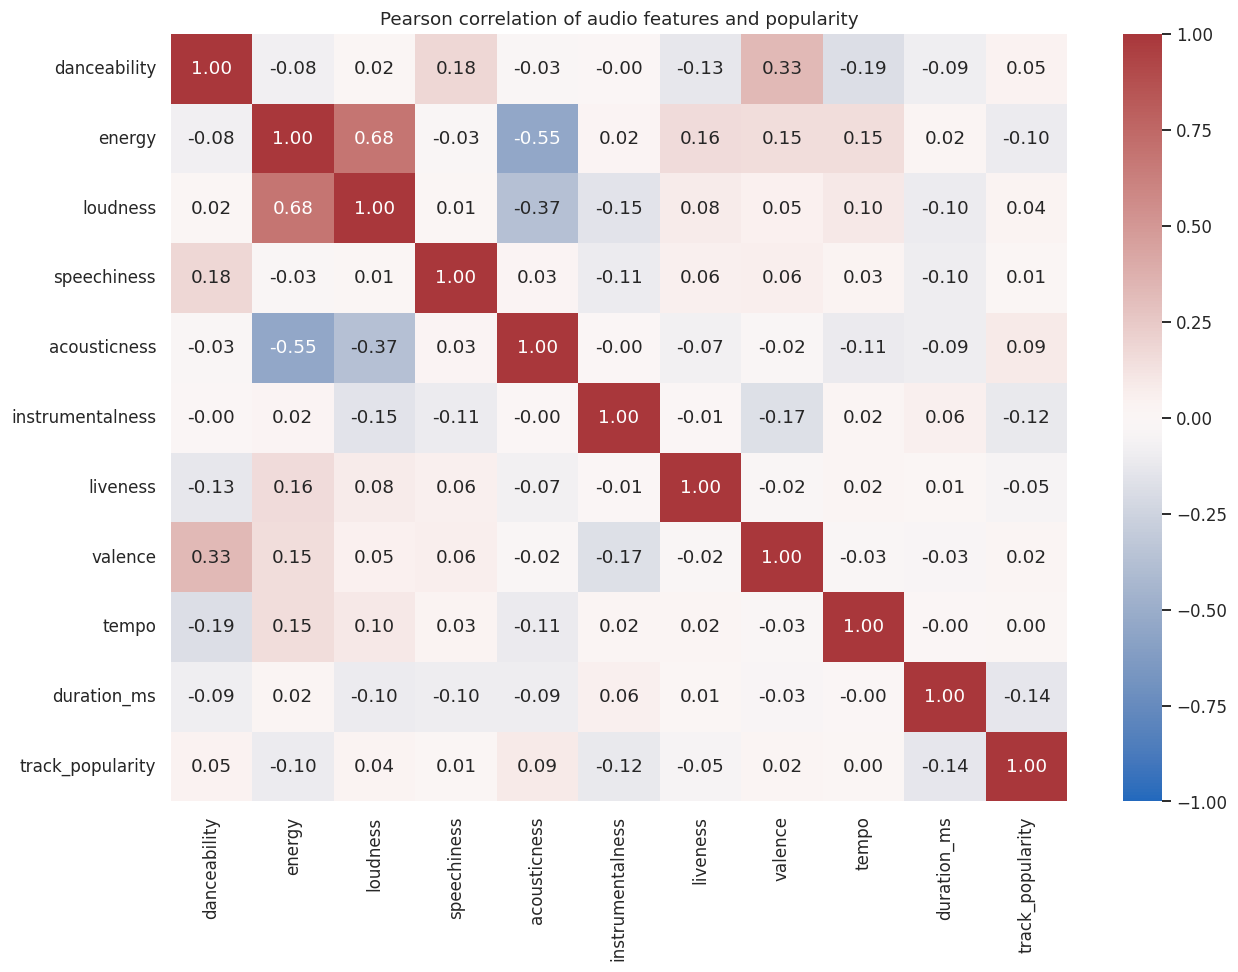

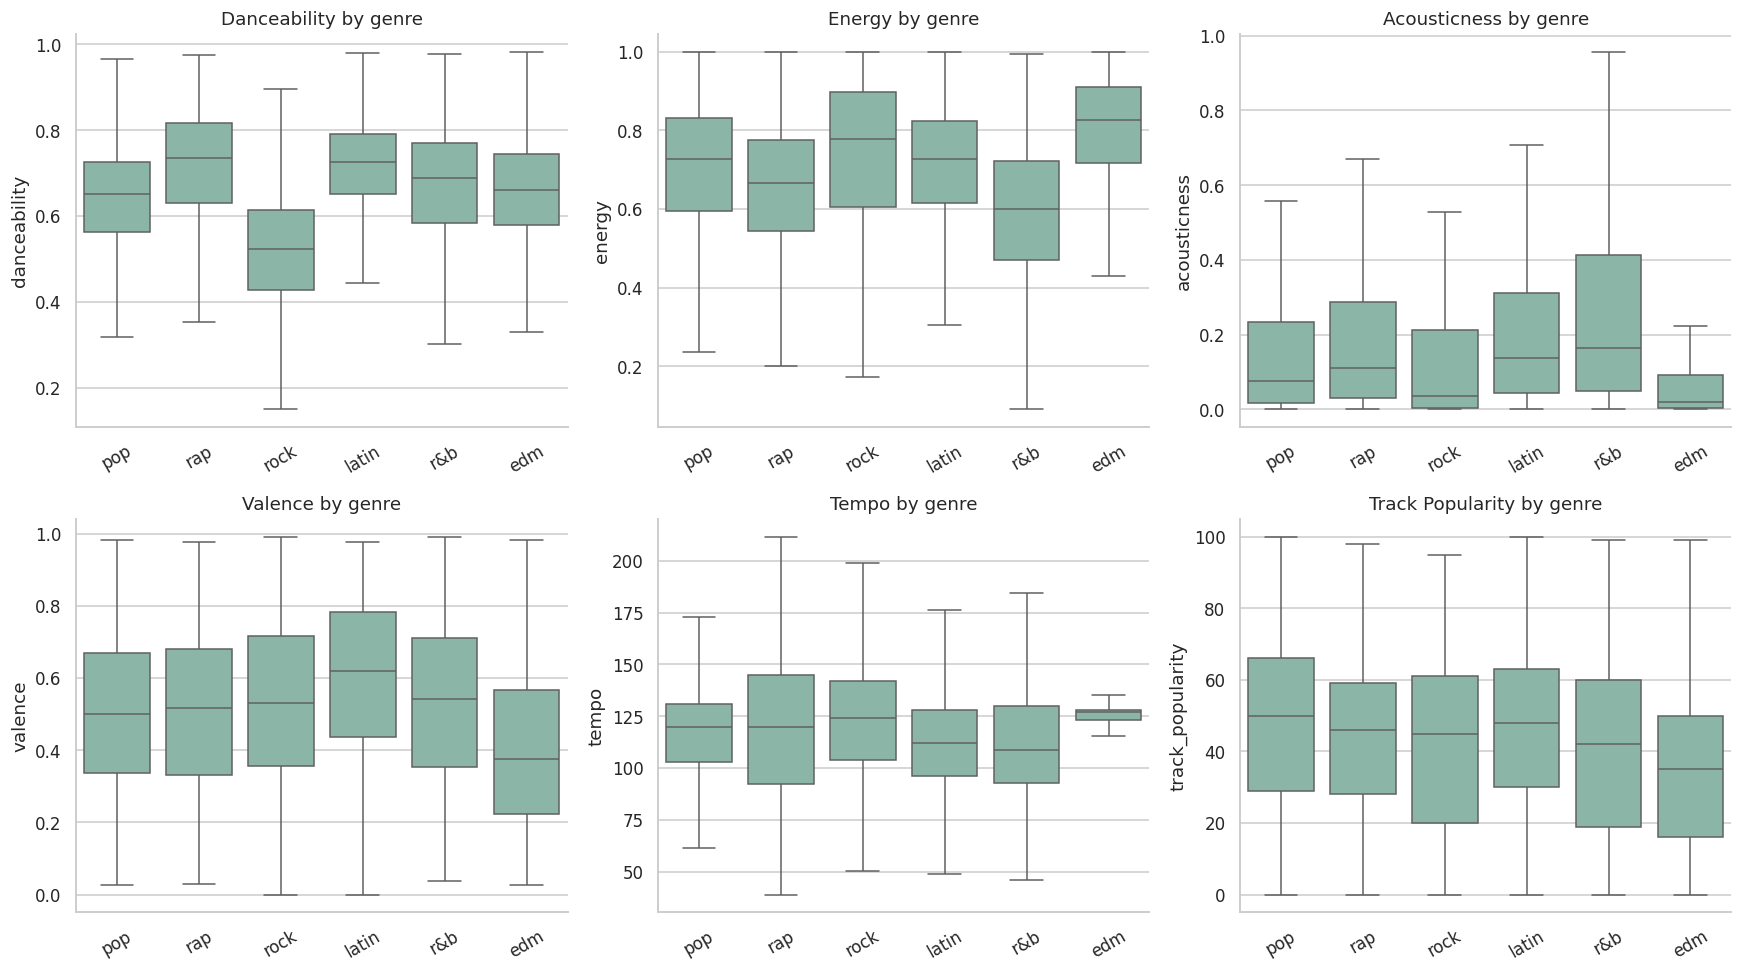

Strongest absolute correlation: energy and loudness (r = 0.682). Correlation does not establish causation.


In [ ]:
correlation = songs[AUDIO_FEATURES + ["track_popularity"]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Pearson correlation of audio features and popularity")
plt.tight_layout()
plt.show()

genre_tracks = memberships[["track_id", "playlist_genre"]].drop_duplicates().merge(
    songs, on="track_id", validate="many_to_one")
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, ["danceability", "energy", "acousticness", "valence", "tempo", "track_popularity"]):
    sns.boxplot(data=genre_tracks, x="playlist_genre", y=feature, color="#84bda9",
                showfliers=False, ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by genre")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
strongest = pairs.abs().idxmax()
print(f"Strongest absolute correlation: {strongest[0]} and {strongest[1]} "
      f"(r = {pairs.loc[strongest]:.3f}). Correlation does not establish causation.")

## 5. Scale the audio features
K-Means groups points by squared Euclidean distance. Without scaling, milliseconds and tempo could outweigh features measured between zero and one. Median imputation and standardization are fitted to the unique-track catalogue. This is an exploratory segmentation of the full catalogue, rather than a supervised prediction task with a train/test accuracy score.

In [ ]:
preprocessor = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
X = preprocessor.fit_transform(songs[AUDIO_FEATURES])
assert np.isfinite(X).all()
display(pd.DataFrame({"feature": AUDIO_FEATURES, "scaled_mean": X.mean(axis=0),
                      "scaled_std": X.std(axis=0)}).round(6))

,feature,scaled_mean,scaled_std
0,danceability,-0.0,1.0
1,energy,0.0,1.0
2,loudness,0.0,1.0
3,speechiness,0.0,1.0
4,acousticness,-0.0,1.0
5,instrumentalness,0.0,1.0
6,liveness,0.0,1.0
7,valence,-0.0,1.0
8,tempo,0.0,1.0
9,duration_ms,0.0,1.0


## 6. Choose the number of clusters
K values from 2 to 10 are compared using full-catalogue K-Means fits. The elbow plot shows inertia, which decreases as K increases. The silhouette score measures separation relative to within-cluster distances; higher is better.

To keep the notebook practical on a free CPU runtime, silhouette scores use the same fixed random sample of up to 2,000 tracks for every candidate. The selected K has the highest sampled silhouette score in the tested range. This is a reproducible baseline choice, not proof of a uniquely correct number of musical groups. K is not forced to equal the number of playlist genres.

K= 2 | sampled silhouette=0.1681
K= 3 | sampled silhouette=0.1231
K= 4 | sampled silhouette=0.1307
K= 5 | sampled silhouette=0.1321
K= 6 | sampled silhouette=0.1351
K= 7 | sampled silhouette=0.1236
K= 8 | sampled silhouette=0.1179
K= 9 | sampled silhouette=0.1216
K=10 | sampled silhouette=0.1219


,k,inertia,silhouette_sample,davies_bouldin,calinski_harabasz
0,2,244276.7625,0.1681,2.2197,4554.5120
1,3,220387.2521,0.1231,2.1994,4060.4799
2,4,202112.0691,0.1307,1.9770,3806.0610
3,5,186581.2377,0.1321,1.8422,3681.9440
4,6,175513.1032,0.1351,1.7363,3488.7037
5,7,166985.4484,0.1236,1.7669,3296.8743
6,8,160229.3391,0.1179,1.7325,3115.6806
7,9,154186.3479,0.1216,1.6919,2971.8290
8,10,148821.5925,0.1219,1.6464,2850.2664


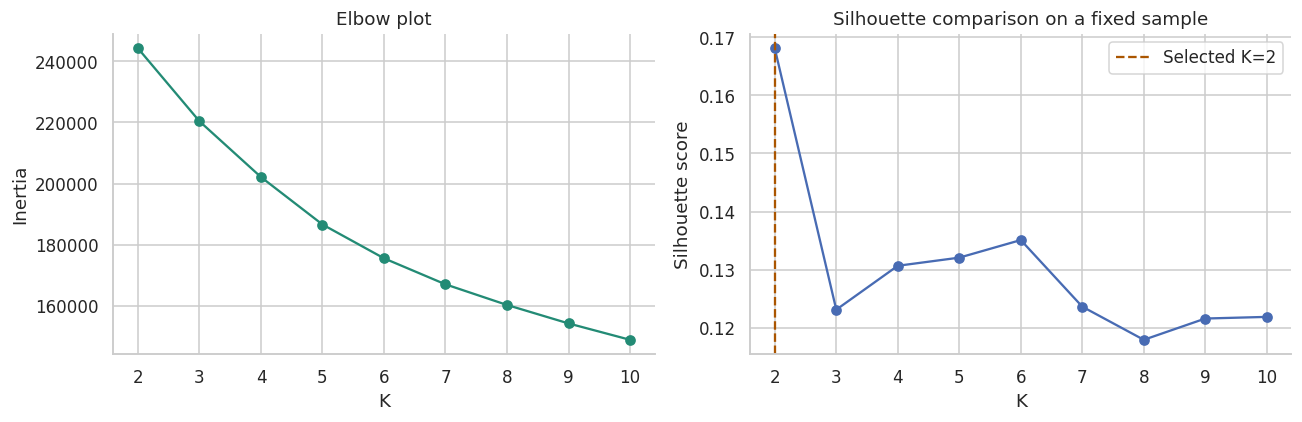

Selected K: 2


In [ ]:
rng = np.random.default_rng(SEED)
evaluation_indices = rng.choice(len(X), size=min(2000, len(X)), replace=False)
results, candidate_models = [], {}
with threadpool_limits(limits=2):
    for k in range(2, 11):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=10, max_iter=300)
        labels = model.fit_predict(X)
        sampled_labels = labels[evaluation_indices]
        score = silhouette_score(X[evaluation_indices], sampled_labels)
        results.append({"k": k, "inertia": model.inertia_, "silhouette_sample": score,
                        "davies_bouldin": davies_bouldin_score(X, labels),
                        "calinski_harabasz": calinski_harabasz_score(X, labels)})
        candidate_models[k] = model
        print(f"K={k:2d} | sampled silhouette={score:.4f}")
scores = pd.DataFrame(results)
best_k = int(scores.loc[scores.silhouette_sample.idxmax(), "k"])
kmeans = candidate_models[best_k]
songs["cluster"] = kmeans.labels_
display(scores.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scores.k, scores.inertia, "o-", color="#238b75")
axes[0].set(title="Elbow plot", xlabel="K", ylabel="Inertia")
axes[1].plot(scores.k, scores.silhouette_sample, "o-", color="#486bb3")
axes[1].axvline(best_k, linestyle="--", color="#aa5500", label=f"Selected K={best_k}")
axes[1].set(title="Silhouette comparison on a fixed sample", xlabel="K", ylabel="Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Selected K:", best_k)

## 7. Check stability and inspect cluster profiles
The selected model is compared with two additional random seeds. Adjusted Rand Index (ARI) compares the assignments while allowing cluster numbers to be permuted. Values near one mean similar partitions. This checks sensitivity to initialization; it does not validate genre correctness.

Cluster numbers are arbitrary identifiers. The standardized profile heatmap shows which features are higher or lower than the catalogue average. Descriptive labels below are relative summaries of the two most distinctive average features.

,seed,adjusted_rand_index
0,7,1.0000
1,21,0.9999


,tracks,mean_popularity,mean_duration_min,share_percent,profile
cluster,,,,,
0,19954,38.833,3.759,70.38,Higher energy / Higher loudness
1,8398,40.529,3.818,29.62,Lower energy / Lower loudness


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
cluster,,,,,,,,,,
0,0.651,0.787,-5.550,0.106,0.093,0.082,0.206,0.532,124.089,225510.570
1,0.658,0.489,-9.829,0.111,0.378,0.113,0.156,0.458,113.533,229102.885


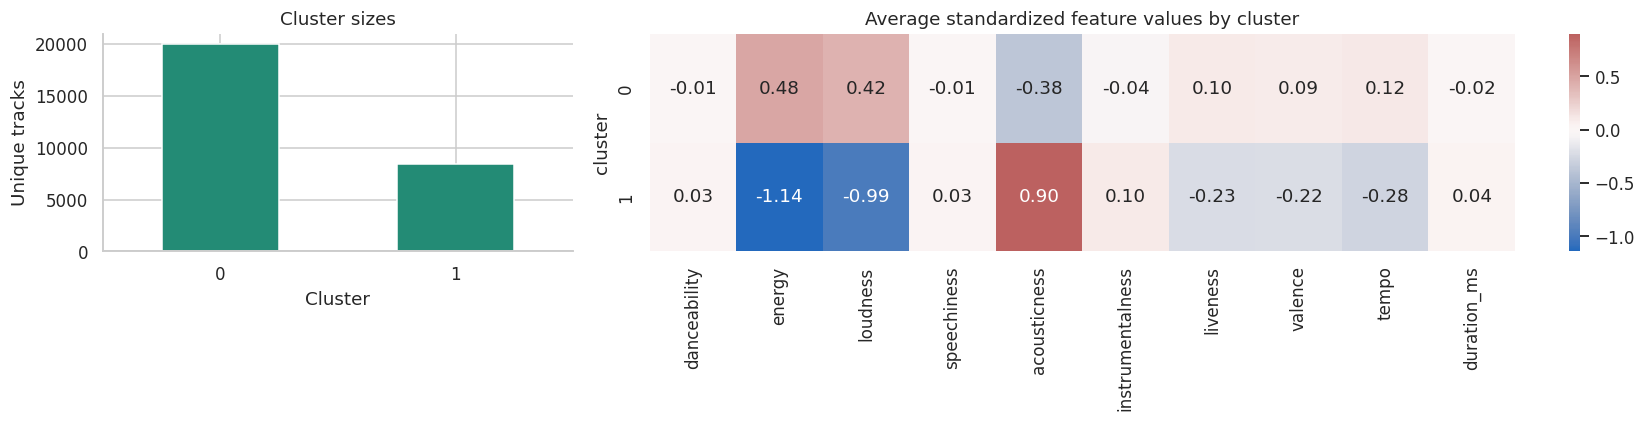

In [ ]:
stability = []
with threadpool_limits(limits=2):
    for seed in [7, 21]:
        other = KMeans(n_clusters=best_k, n_init=10, random_state=seed).fit_predict(X)
        stability.append({"seed": seed, "adjusted_rand_index": adjusted_rand_score(songs.cluster, other)})
display(pd.DataFrame(stability).round(4))

cluster_means = songs.groupby("cluster")[AUDIO_FEATURES].mean()
scaled_profiles = pd.DataFrame(X, columns=AUDIO_FEATURES).assign(
    cluster=songs.cluster).groupby("cluster").mean()
cluster_labels = {}
for cluster, row in scaled_profiles.iterrows():
    distinctive = row.abs().nlargest(2).index
    cluster_labels[int(cluster)] = " / ".join(
        ("Higher " if row[feature] > 0 else "Lower ") + feature.replace("_", " ")
        for feature in distinctive)
songs["cluster_profile"] = songs.cluster.map(cluster_labels)
cluster_summary = songs.groupby("cluster").agg(
    tracks=("track_id", "size"), mean_popularity=("track_popularity", "mean"),
    mean_duration_min=("duration_min", "mean"))
cluster_summary["share_percent"] = cluster_summary.tracks / len(songs) * 100
cluster_summary["profile"] = cluster_summary.index.map(cluster_labels)
display(cluster_summary.round(3))
display(cluster_means.round(3))
fig, axes = plt.subplots(1, 2, figsize=(16, max(4, best_k * 0.65)),
                         gridspec_kw={"width_ratios": [1, 2.3]})
cluster_summary.tracks.plot.bar(ax=axes[0], color="#238b75", rot=0)
axes[0].set(title="Cluster sizes", xlabel="Cluster", ylabel="Unique tracks")
sns.heatmap(scaled_profiles, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Average standardized feature values by cluster")
plt.tight_layout()
plt.show()

## 8. Visualize the clusters with PCA
PCA projects the ten standardized audio features onto two axes for visualization. K-Means is fitted in the full ten-feature space. Overlap in this two-dimensional plot does not by itself mean identical groups in the full space.

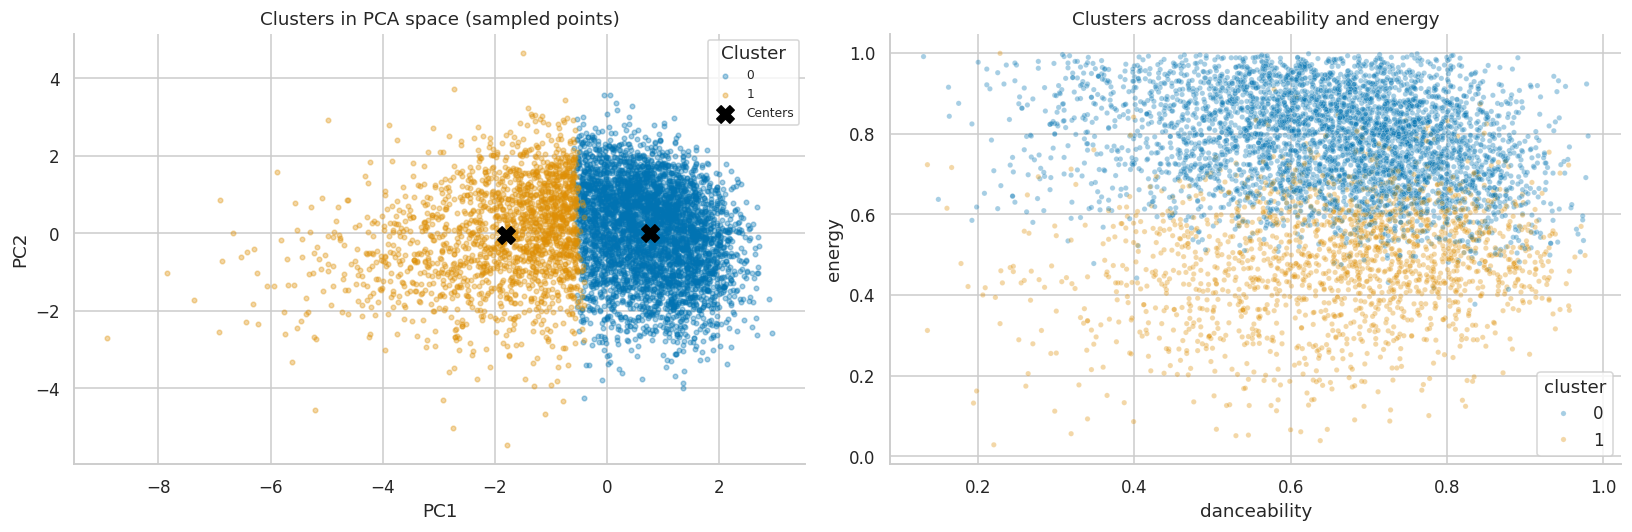

Variance retained by two PCA components: 37.1%


In [ ]:
pca = PCA(n_components=2, random_state=SEED)
coordinates = pca.fit_transform(X)
plot_df = songs[["cluster"]].copy()
plot_df[["PC1", "PC2"]] = coordinates
plot_sample = plot_df.sample(min(6000, len(plot_df)), random_state=SEED)
colors = sns.color_palette("colorblind", n_colors=best_k)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for cluster in range(best_k):
    group = plot_sample[plot_sample.cluster == cluster]
    axes[0].scatter(group.PC1, group.PC2, s=9, alpha=0.35, color=colors[cluster], label=str(cluster))
centers = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centers[:, 0], centers[:, 1], marker="X", s=130, color="black", label="Centers")
axes[0].set(title="Clusters in PCA space (sampled points)", xlabel="PC1", ylabel="PC2")
axes[0].legend(title="Cluster", fontsize=8)
sns.scatterplot(data=songs.sample(min(6000, len(songs)), random_state=SEED),
                x="danceability", y="energy", hue="cluster", palette=dict(enumerate(colors)),
                alpha=0.35, s=12, ax=axes[1])
axes[1].set_title("Clusters across danceability and energy")
plt.tight_layout()
plt.show()
print(f"Variance retained by two PCA components: {pca.explained_variance_ratio_.sum():.1%}")

## 9. Compare clusters with genres and playlist names
Each genre row shows the percentage of its unique tracks assigned to each cluster. The playlist chart uses the 12 largest playlists by unique track count. Playlist IDs are retained to distinguish different playlists with the same name.

Playlist genre is contextual metadata, not a verified exclusive label for each track. Mixed clusters are expected when songs from different genres have similar audio features. These comparisons are descriptive, rather than classification accuracy scores.

cluster,0,1
playlist_genre,,
edm,4900,637
latin,3448,1191
pop,3838,1294
r&b,2541,2597
rap,3586,1897
rock,3130,1321


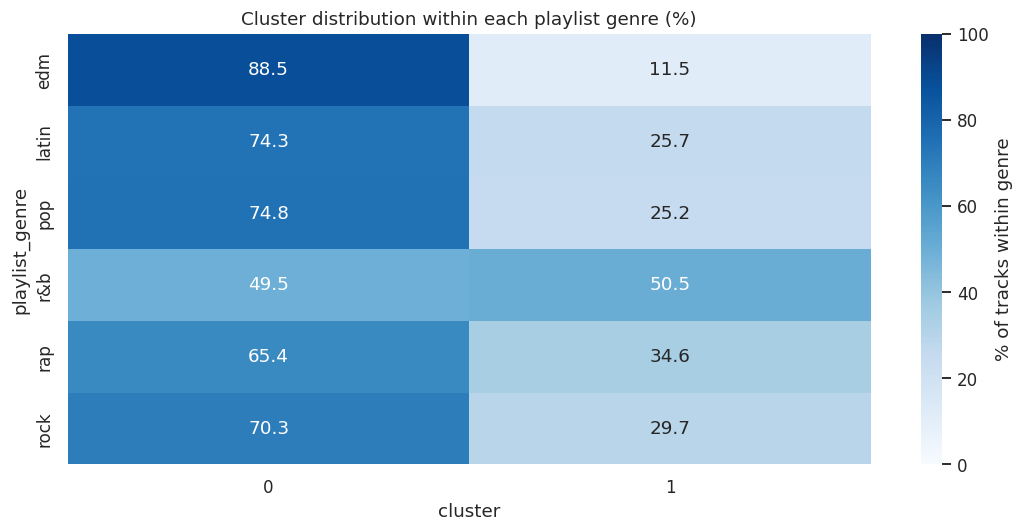

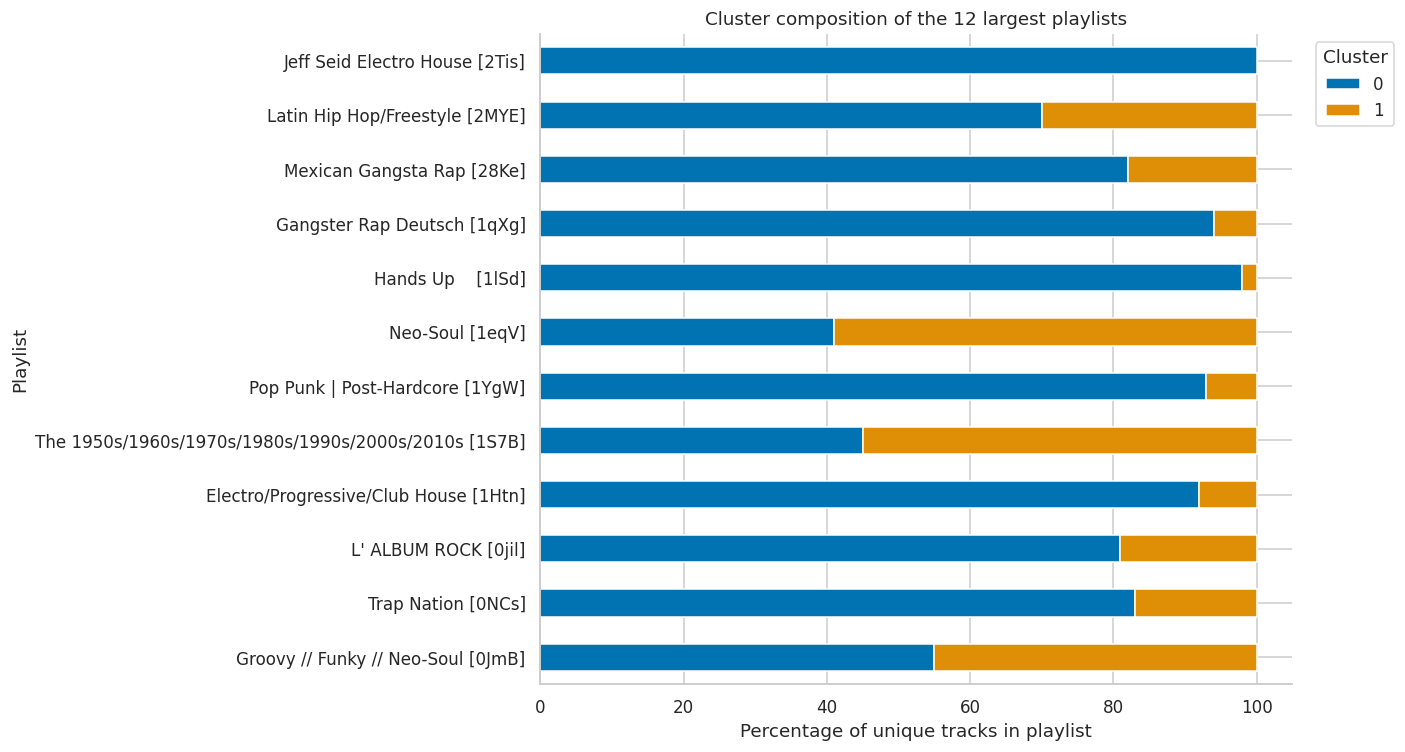

In [ ]:
genre_cluster_rows = memberships[["track_id", "playlist_genre"]].drop_duplicates().merge(
    songs[["track_id", "cluster"]], on="track_id", validate="many_to_one")
genre_cluster_counts = pd.crosstab(genre_cluster_rows.playlist_genre, genre_cluster_rows.cluster)
genre_cluster_pct = genre_cluster_counts.div(genre_cluster_counts.sum(axis=1), axis=0) * 100
display(genre_cluster_counts)
plt.figure(figsize=(10, 5))
sns.heatmap(genre_cluster_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% of tracks within genre"})
plt.title("Cluster distribution within each playlist genre (%)")
plt.tight_layout()
plt.show()

playlist_cluster_rows = memberships[["track_id", "playlist_id", "playlist_name"]].drop_duplicates().merge(
    songs[["track_id", "cluster"]], on="track_id", validate="many_to_one")
top_ids = playlist_cluster_rows.groupby("playlist_id").track_id.nunique().nlargest(12).index
playlist_counts = pd.crosstab(playlist_cluster_rows.playlist_id, playlist_cluster_rows.cluster).loc[top_ids]
playlist_pct = playlist_counts.div(playlist_counts.sum(axis=1), axis=0) * 100
name_lookup = memberships.drop_duplicates("playlist_id").set_index("playlist_id").playlist_name
playlist_pct.index = [f"{str(name_lookup.loc[p])[:45]} [{p[:4]}]" for p in playlist_pct.index]
playlist_pct.plot.barh(stacked=True, figsize=(13, 7), color=colors)
plt.xlabel("Percentage of unique tracks in playlist")
plt.ylabel("Playlist")
plt.title("Cluster composition of the 12 largest playlists")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 10. Representative songs
Songs nearest their own cluster center provide examples of each sound profile. Distance is measured in standardized audio-feature space.

In [ ]:
distances_to_center = np.linalg.norm(X - kmeans.cluster_centers_[songs.cluster.to_numpy()], axis=1)
songs["distance_to_center"] = distances_to_center
representatives = (songs.sort_values(["cluster", "distance_to_center"])
                   .groupby("cluster", group_keys=False).head(3))
display(representatives[["cluster", "cluster_profile", "track_name", "track_artist",
                         "playlist_genres", "distance_to_center"]].round(3))

,cluster,cluster_profile,track_name,track_artist,playlist_genres,distance_to_center
48,0,Higher energy / Higher loudness,American Boy - Brooks Remix,Estelle,pop,0.723
27998,0,Higher energy / Higher loudness,Always On My Mind - Nihil Young Remix,Mike Mago,edm,0.724
12946,0,Higher energy / Higher loudness,Lying Is the Most Fun a Girl Can Have Without Takin...,Panic! At The Disco,rock,0.759
15590,1,Lower energy / Lower loudness,"Cruise - From ""Fifty Shades Darker (Original Motion...",Kygo,latin,0.996
1953,1,Lower energy / Lower loudness,Wild Girl,Kito,pop,1.057
9427,1,Lower energy / Lower loudness,Anos Luz,Matuê,rap,1.083


## 11. Content-based recommendation
For a selected track ID, the recommender finds other tracks in its cluster and ranks them by Euclidean distance in the same standardized feature space. The seed track is excluded, and duplicate song–artist pairs are removed from the suggestions. Smaller distances indicate closer measured audio profiles, not a probability of enjoyment.

Restricting candidates to one cluster keeps the approach simple, but can miss similar songs across a cluster boundary. Different recordings or remixes may still have separate track IDs. Title search returns all matches so an ambiguous name is not silently treated as one song.

,track_id,track_name,track_artist,cluster
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxury Remix,Ed Sheeran,0
5,7fvUMiyapMsRRxr07cU8Ef,Beautiful People (feat. Khalid) - Jack Wins Remix,Ed Sheeran,0
10,3eFJI470ALf1EYjywPRsJy,Cross Me (feat. Chance the Rapper & PnB Rock) - M-2...,Ed Sheeran,0
15,1EJgymgJHcjSOGSHcYaxvW,South of the Border (feat. Camila Cabello & Cardi B...,Ed Sheeran,0
78,3vQhEd4lOg4mAV6CHCgoHW,South of the Border (feat. Camila Cabello & Cardi B...,Ed Sheeran,0
226,19TOAlTFq0NDHvUPQR0tkr,South of the Border (feat. Camila Cabello & Cardi B...,Ed Sheeran,0
315,1uuUnsWpJwqBh5GRQ8uxla,Happier - Tiësto’s AFTR:HRS Remix,Ed Sheeran,0
1218,7qiZfU4dY1lWllzX7mPBI3,Shape of You,Ed Sheeran,0
1305,70eFcWOvlMObDhURTqT4Fv,Beautiful People (feat. Khalid),Ed Sheeran,0
1311,4vUmTMuQqjdnvlZmAH61Qk,South of the Border (feat. Camila Cabello & Cardi B),Ed Sheeran,0


Seed: I Don't Care (with Justin Bieber) - Loud Luxury Remix — Ed Sheeran


,track_id,track_name,track_artist,playlist_genres,cluster,audio_distance
0,1CSk9lJFJt4OdcvOH5iK61,I Miss You (feat. Julia Michaels) - Cahill Remix,Clean Bandit,edm,0,0.3167
1,3OqmsGnX4EdHq0nD04B2CR,Name & Number,Shift K3Y,pop,0,0.5442
2,5wPhERt9izm1T45aFXDWPe,Todavia,La Factoria,latin,0,0.6207
3,2KrJDONq4Hq1JKlmvQe22H,Love With Your Life (Capital Kings Remix),Hollyn,edm,0,0.6411
4,7LJjWqhqK594nN7qJzLVXE,As If It's Your Last,BLACKPINK,pop,0,0.6730


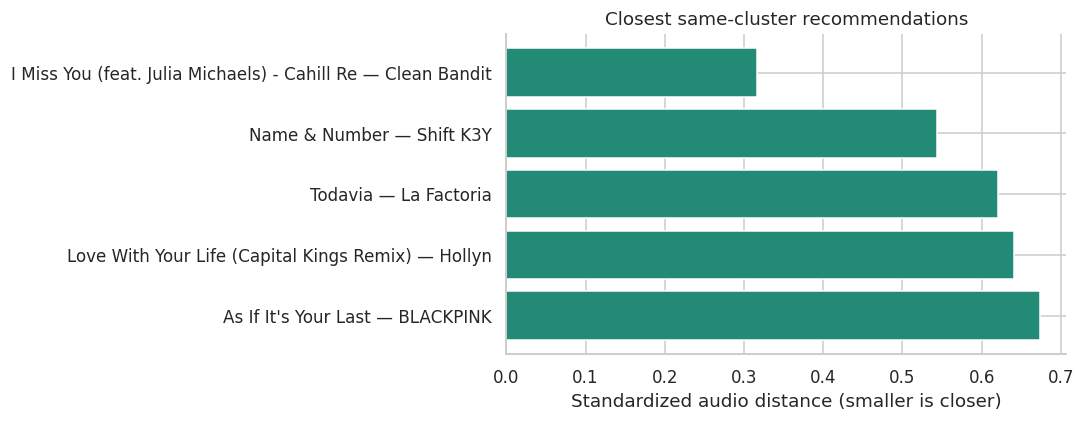

In [ ]:
def search_songs(query, limit=10):
    """Find a literal title or artist fragment, without regex interpretation."""
    mask = (songs.track_name.str.contains(str(query), case=False, regex=False, na=False)
            | songs.track_artist.str.contains(str(query), case=False, regex=False, na=False))
    return songs.loc[mask, ["track_id", "track_name", "track_artist", "cluster"]].head(limit)


def recommend_songs(track_id, n=5):
    """Rank distinct songs from the seed's cluster using standardized audio distance."""
    if not isinstance(n, int) or isinstance(n, bool) or n < 1:
        raise ValueError("n must be a positive integer.")
    matches = songs.index[songs.track_id.eq(track_id)]
    if len(matches) == 0:
        raise ValueError("Track ID not found; use search_songs() to find a valid ID.")
    seed_index = int(matches[0])
    seed = songs.loc[seed_index]
    candidate_indices = songs.index[(songs.cluster == seed.cluster) & (songs.track_id != track_id)]
    result = songs.loc[candidate_indices].copy()
    result["audio_distance"] = np.linalg.norm(X[candidate_indices] - X[seed_index], axis=1)
    result = result.sort_values(["audio_distance", "track_id"], kind="stable")
    normalized_name = result.track_name.str.strip().str.casefold()
    normalized_artist = result.track_artist.str.strip().str.casefold()
    same_recording = ((normalized_name == seed.track_name.strip().casefold())
                      & (normalized_artist == seed.track_artist.strip().casefold()))
    result = result.loc[~same_recording].copy()
    result["_identity"] = (result.track_name.str.strip().str.casefold() + " | "
                           + result.track_artist.str.strip().str.casefold())
    result = result.drop_duplicates("_identity").head(n)
    return result[["track_id", "track_name", "track_artist", "playlist_genres",
                   "cluster", "audio_distance"]].reset_index(drop=True)

display(search_songs("Ed Sheeran"))
seed_track = songs.iloc[0]
print(f"Seed: {seed_track.track_name} — {seed_track.track_artist}")
recommendations = recommend_songs(seed_track.track_id, n=5)
display(recommendations.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
labels = (recommendations.track_name.str.slice(0, 45) + " — "
          + recommendations.track_artist.str.slice(0, 22))
ax.barh(labels.iloc[::-1], recommendations.audio_distance.iloc[::-1], color="#238b75")
ax.set(title="Closest same-cluster recommendations", xlabel="Standardized audio distance (smaller is closer)")
plt.tight_layout()
plt.show()

## 12. Validation and reproducibility
These checks verify that each track has one assignment, the stored preprocessing pipeline reproduces the fitted labels, and the recommender excludes the seed and returns ordered, unique IDs. They verify implementation behavior; they do not measure whether a listener likes a suggestion.

In [ ]:
assert songs.track_id.is_unique
assert songs.cluster.notna().all()
assert songs.cluster.nunique() == best_k
assert cluster_summary.tracks.sum() == len(songs)
with threadpool_limits(limits=2):
    predicted = kmeans.predict(preprocessor.transform(songs[AUDIO_FEATURES]))
assert np.array_equal(predicted, songs.cluster.to_numpy())
assert seed_track.track_id not in recommendations.track_id.values
assert recommendations.track_id.is_unique
assert recommendations.audio_distance.is_monotonic_increasing
assert recommendations.cluster.eq(seed_track.cluster).all()
assert len(recommendations) == 5
assert len(search_songs("[literal unmatched search]")) == 0
try:
    recommend_songs("not-a-real-track-id")
except ValueError:
    pass
else:
    raise AssertionError("Unknown IDs must raise a clear error.")
print("All data, assignment, preprocessing, and recommendation checks passed.")

All data, assignment, preprocessing, and recommendation checks passed.


## 13. Results and discussion
The following summary is calculated from the current run. It avoids hard-coded cluster claims, because cluster assignments can vary slightly between numerical library versions.

In [ ]:
selected_score = scores.loc[scores.k.eq(best_k)].iloc[0]
largest_cluster = int(cluster_summary.tracks.idxmax())
lines = [
    f"The source contains **{len(raw_df):,} records**. After identity cleaning and track-level consolidation, "
    f"**{len(songs):,} unique tracks** are used for clustering.",
    f"Among K=2 to 10, **K={best_k}** gives the highest sampled silhouette score "
    f"(**{selected_score.silhouette_sample:.3f}**). Davies–Bouldin is "
    f"**{selected_score.davies_bouldin:.3f}** (lower is preferable); "
    f"Calinski–Harabasz is **{selected_score.calinski_harabasz:.1f}** (higher is preferable). "
    "These are internal clustering measures, not prediction accuracy. ",
    f"The largest group is cluster **{largest_cluster}**, containing "
    f"**{cluster_summary.loc[largest_cluster, 'share_percent']:.1f}%** of tracks. "
    f"Its relative profile is **{cluster_labels[largest_cluster]}**."]
for cluster in cluster_summary.index:
    lines.append(f"Cluster **{cluster}** contains **{int(cluster_summary.loc[cluster, 'tracks']):,}** tracks: "
                 f"{cluster_labels[int(cluster)]}.")
for genre, row in genre_cluster_pct.iterrows():
    dominant = int(row.idxmax())
    lines.append(f"For **{genre}** playlist memberships, cluster **{dominant}** has the largest share "
                 f"(**{row.max():.1f}%**).")
lines.append("The silhouette score is modest: the groups overlap substantially. "
             "The selected segmentation is a coarse sound-profile baseline rather than strong genre separation.")
lines.append(f"The mean initialization-stability ARI across the two additional seeds is "
             f"**{np.mean([item['adjusted_rand_index'] for item in stability]):.3f}**.")
display(Markdown("\n\n".join(lines)))

The source contains **32,833 records**. After identity cleaning and track-level consolidation, **28,352 unique tracks** are used for clustering.

Among K=2 to 10, **K=2** gives the highest sampled silhouette score (**0.168**). Davies–Bouldin is **2.220** (lower is preferable); Calinski–Harabasz is **4554.5** (higher is preferable). These are internal clustering measures, not prediction accuracy. 

The largest group is cluster **0**, containing **70.4%** of tracks. Its relative profile is **Higher energy / Higher loudness**.

Cluster **0** contains **19,954** tracks: Higher energy / Higher loudness.

Cluster **1** contains **8,398** tracks: Lower energy / Lower loudness.

For **edm** playlist memberships, cluster **0** has the largest share (**88.5%**).

For **latin** playlist memberships, cluster **0** has the largest share (**74.3%**).

For **pop** playlist memberships, cluster **0** has the largest share (**74.8%**).

For **r&b** playlist memberships, cluster **1** has the largest share (**50.5%**).

For **rap** playlist memberships, cluster **0** has the largest share (**65.4%**).

For **rock** playlist memberships, cluster **0** has the largest share (**70.3%**).

The silhouette score is modest: the groups overlap substantially. The selected segmentation is a coarse sound-profile baseline rather than strong genre separation.

The mean initialization-stability ARI across the two additional seeds is **1.000**.

## 14. Conclusion and limitations
The project produces a reproducible song segmentation and a working audio-similarity recommendation baseline. Cluster profiles, genre comparisons, representative tracks, and nearest-song examples make the results inspectable.

- Audio clusters should be described as sound profiles rather than definitive genres. Playlist labels can overlap.
- Scaling gives each input feature equal variance, but does not guarantee equal musical importance. Correlated features may receive extra weight.
- K-Means favors roughly spherical groups and is sensitive to unusual values and feature choices. The chosen K depends on the tested range and sampled silhouette criterion.
- This is a historical dataset snapshot. Popularity values and catalogue coverage are not current Spotify statistics.
- The recommender has no user preferences, listening history, lyrics, or audio embeddings. Listening feedback would be needed to evaluate practical relevance.

Possible extensions include a global nearest-neighbor baseline, alternative scaling, more suitable representations of musical key, and user evaluation of recommended songs.

## 15. Export the project results
This cell writes the clustered catalogue, membership-level cluster assignments, cluster summaries, candidate scores, recommendations, and fitted model into `spotify_project_outputs`. The model bundle contains the feature order and preprocessing pipeline needed to transform another compatible track. Reload serialized models only from trusted sources and preferably in the same package versions.

In [ ]:
output_dir = Path("spotify_project_outputs")
output_dir.mkdir(exist_ok=True)
songs.to_csv(output_dir / "clustered_songs.csv", index=False)
memberships.merge(songs[["track_id", "cluster"]], on="track_id", validate="many_to_one").to_csv(
    output_dir / "playlist_cluster_assignments.csv", index=False)
cluster_summary.to_csv(output_dir / "cluster_summary.csv")
cluster_means.to_csv(output_dir / "cluster_audio_means.csv")
scores.to_csv(output_dir / "k_selection_scores.csv", index=False)
recommendations.to_csv(output_dir / "example_recommendations.csv", index=False)
bundle = {"features": AUDIO_FEATURES, "preprocessor": preprocessor,
          "kmeans": kmeans, "cluster_labels": cluster_labels,
          "versions": {"python": platform.python_version(), "numpy": np.__version__,
                       "pandas": pd.__version__, "scikit_learn": sklearn.__version__}}
joblib.dump(bundle, output_dir / "spotify_kmeans_model.joblib")
(output_dir / "run_summary.json").write_text(json.dumps({
    "source_records": len(raw_df), "unique_tracks": len(songs), "selected_k": best_k,
    "sampled_silhouette": float(selected_score.silhouette_sample),
    "pca_variance_retained": float(pca.explained_variance_ratio_.sum()),
    "seed": SEED, "versions": bundle["versions"]}, indent=2))
reloaded = joblib.load(output_dir / "spotify_kmeans_model.joblib")
with threadpool_limits(limits=2):
    assert np.array_equal(reloaded["kmeans"].predict(
        reloaded["preprocessor"].transform(songs[AUDIO_FEATURES].head(20))),
        songs.cluster.head(20).to_numpy())
print("Exports saved successfully; saved-model reload check passed.")
print("\n".join(str(path) for path in sorted(output_dir.iterdir())))

Exports saved successfully; saved-model reload check passed.
spotify_project_outputs/cluster_audio_means.csv
spotify_project_outputs/cluster_summary.csv
spotify_project_outputs/clustered_songs.csv
spotify_project_outputs/example_recommendations.csv
spotify_project_outputs/k_selection_scores.csv
spotify_project_outputs/playlist_cluster_assignments.csv
spotify_project_outputs/run_summary.json
spotify_project_outputs/spotify_kmeans_model.joblib


## References
1. **Corizo project brief:** `Project 2 - Spotify Genre Grouping.docx`, supplied in the project ZIP. Requirements: preprocessing, exploratory visualizations, correlation matrix, genre/playlist cluster comparisons, and a model supporting recommendations.
2. **Dataset:** `spotify dataset.csv`, supplied in the same ZIP. The supplied file is the source used in this notebook; its original collection method and license are not specified in the brief.
3. **Suggested reference:** Sivar Azadi, [K-Means Spotify Song Clustering](https://www.kaggle.com/code/sivarazadi/k-means-spotify-song-clustering#Cluster-Characteristics), Kaggle. The linked page identifies a different input dataset, Spotify 1.2M+ Songs. This project follows the supplied smaller dataset and brief; it does not reproduce that notebook's numerical results. The full reference code was not available for inspection during preparation.
4. **Method documentation:** [scikit-learn K-Means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), and [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).